In [4]:

# Notebook 03: Appointment No-Show Prediction
# Step 7.2: Machine Learning Environment Setup

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from google.colab import files

print("Machine Learning environment ready!")

uploaded = files.upload()


Machine Learning environment ready!


Saving cleaned_data.zip to cleaned_data (1).zip


In [5]:

# Step 7.3: Machine Learning Data Preparation

# Extract cleaned datasets
with zipfile.ZipFile("cleaned_data.zip", "r") as zip_ref:
    zip_ref.extractall("/content/cleaned_data")

# Load master dataset
df = pd.read_csv(
    "/content/cleaned_data/master_dataset.csv"
)

# Retain known appointment outcomes
ml_df = df[df["status"].isin(
    ["Attended", "No-Show"]
)].copy()

# Create binary target variable
ml_df["target"] = ml_df["status"].map({
    "Attended": 0,
    "No-Show": 1
})

# Display preparation report
print("MACHINE LEARNING DATA REPORT")
print("=" * 45)

print("Original records:", len(df))
print("Records for ML:", len(ml_df))
print("Unknown outcomes excluded:", len(df) - len(ml_df))

print("\nTARGET DISTRIBUTION")
print(ml_df["target"].value_counts())

print("\nData preparation completed successfully!")


MACHINE LEARNING DATA REPORT
Original records: 1000
Records for ML: 996
Unknown outcomes excluded: 4

TARGET DISTRIBUTION
target
0    777
1    219
Name: count, dtype: int64

Data preparation completed successfully!


In [6]:

# Step 7.4: Feature Selection

# Numerical features
numerical_features = [
    "age",
    "distance_km",
    "fee_inr",
    "prior_no_shows",
    "lead_time_days"
]

# Categorical features
categorical_features = [
    "gender",
    "booking_channel",
    "visit_type",
    "reminder_sent",
    "city",
    "tier"
]

# Combine selected features
features = numerical_features + categorical_features

# Input variables
X = ml_df[features].copy()

# Target variable
y = ml_df["target"].astype(int)

print("FEATURE SELECTION REPORT")
print("=" * 40)

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Total features:", len(features))

print("\nInput data shape:", X.shape)
print("Target data shape:", y.shape)

print("\nSELECTED FEATURES")
print(features)

print("\nMISSING VALUES IN FEATURES")
print(X.isna().sum())

print("\nRepeated patient IDs:",
      ml_df["patient_id"].duplicated().sum())

print("\nFeature selection completed!")


FEATURE SELECTION REPORT
Numerical features: 5
Categorical features: 6
Total features: 11

Input data shape: (996, 11)
Target data shape: (996,)

SELECTED FEATURES
['age', 'distance_km', 'fee_inr', 'prior_no_shows', 'lead_time_days', 'gender', 'booking_channel', 'visit_type', 'reminder_sent', 'city', 'tier']

MISSING VALUES IN FEATURES
age                16
distance_km        20
fee_inr             0
prior_no_shows      0
lead_time_days      6
gender              0
booking_channel     0
visit_type          0
reminder_sent       0
city                0
tier                0
dtype: int64

Repeated patient IDs: 540

Feature selection completed!


In [7]:

# Step 7.5: Patient-Level Train-Test Split

from sklearn.model_selection import GroupShuffleSplit

groups = ml_df["patient_id"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# Check patient overlap
train_patients = set(groups.iloc[train_idx])
test_patients = set(groups.iloc[test_idx])

overlap = train_patients.intersection(test_patients)

assert len(overlap) == 0

print("TRAIN-TEST SPLIT REPORT")
print("=" * 40)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("Unique training patients:", len(train_patients))
print("Unique testing patients:", len(test_patients))

print("Patient overlap:", len(overlap))

print("\nTRAINING TARGET DISTRIBUTION")
print(y_train.value_counts())

print("\nTESTING TARGET DISTRIBUTION")
print(y_test.value_counts())

print("\nPatient-level split completed successfully!")


TRAIN-TEST SPLIT REPORT
Training records: 815
Testing records: 181
Unique training patients: 364
Unique testing patients: 92
Patient overlap: 0

TRAINING TARGET DISTRIBUTION
target
0    634
1    181
Name: count, dtype: int64

TESTING TARGET DISTRIBUTION
target
0    143
1     38
Name: count, dtype: int64

Patient-level split completed successfully!


In [8]:

# Step 7.6: Machine Learning Preprocessing

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing pipelines
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("DATA PREPROCESSING REPORT")
print("=" * 40)

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nMissing numerical values: Median imputation")
print("Missing categorical values: Mode imputation")
print("Numerical scaling: StandardScaler")
print("Categorical encoding: OneHotEncoder")

print("\nPreprocessing pipeline created successfully!")


DATA PREPROCESSING REPORT
Numerical features: 5
Categorical features: 6

Missing numerical values: Median imputation
Missing categorical values: Mode imputation
Numerical scaling: StandardScaler
Categorical encoding: OneHotEncoder

Preprocessing pipeline created successfully!


In [9]:

# Step 7.7: Logistic Regression Model

from sklearn.base import clone

# Create the model pipeline
lr_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model
lr_model.fit(X_train, y_train)

# Generate predictions
lr_pred = lr_model.predict(X_test)
lr_prob = lr_model.predict_proba(X_test)[:, 1]

# Evaluate model performance
lr_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, lr_pred),
    "Precision": precision_score(y_test, lr_pred, zero_division=0),
    "Recall": recall_score(y_test, lr_pred, zero_division=0),
    "F1 Score": f1_score(y_test, lr_pred, zero_division=0),
    "ROC AUC": roc_auc_score(y_test, lr_prob)
}

print("LOGISTIC REGRESSION PERFORMANCE")
print("=" * 45)

for metric, value in lr_results.items():
    if metric == "Model":
        print(metric, ":", value)
    else:
        print(f"{metric}: {value:.4f}")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test, lr_pred,
    target_names=["Attended", "No-Show"],
    zero_division=0
))

print("\nLogistic Regression trained successfully!")


LOGISTIC REGRESSION PERFORMANCE
Model : Logistic Regression
Accuracy: 0.6740
Precision: 0.3385
Recall: 0.5789
F1 Score: 0.4272
ROC AUC: 0.7113

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Attended       0.86      0.70      0.77       143
     No-Show       0.34      0.58      0.43        38

    accuracy                           0.67       181
   macro avg       0.60      0.64      0.60       181
weighted avg       0.75      0.67      0.70       181


Logistic Regression trained successfully!


In [10]:

# Step 7.8: Random Forest Classification

# Create Random Forest pipeline
rf_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

# Generate predictions
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Evaluate model performance
rf_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(
        y_test, rf_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, rf_pred, zero_division=0
    ),
    "F1 Score": f1_score(
        y_test, rf_pred, zero_division=0
    ),
    "ROC AUC": roc_auc_score(y_test, rf_prob)
}

print("RANDOM FOREST PERFORMANCE")
print("=" * 45)

for metric, value in rf_results.items():
    if metric == "Model":
        print(metric, ":", value)
    else:
        print(f"{metric}: {value:.4f}")

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    rf_pred,
    target_names=["Attended", "No-Show"],
    zero_division=0
))

print("\nRandom Forest trained successfully!")


RANDOM FOREST PERFORMANCE
Model : Random Forest
Accuracy: 0.7182
Precision: 0.3415
Recall: 0.3684
F1 Score: 0.3544
ROC AUC: 0.6583

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Attended       0.83      0.81      0.82       143
     No-Show       0.34      0.37      0.35        38

    accuracy                           0.72       181
   macro avg       0.59      0.59      0.59       181
weighted avg       0.73      0.72      0.72       181


Random Forest trained successfully!


In [11]:

# Step 7.9: Model Comparison and Cross-Validation

from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_validate
)

from sklearn.dummy import DummyClassifier

# Patient groups from training data
train_groups = groups.iloc[train_idx]

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "Baseline": DummyClassifier(
        strategy="most_frequent"
    )
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=train_groups,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "recall": "recall",
            "f1": "f1",
            "roc_auc": "roc_auc"
        }
    )

    cv_results.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC AUC": scores["test_roc_auc"].mean()
    })

cv_report = pd.DataFrame(cv_results)

cv_report = cv_report.sort_values(
    "CV ROC AUC", ascending=False
).reset_index(drop=True)

print("CROSS-VALIDATION RESULTS")
display(cv_report.round(4))

best_model_name = cv_report.loc[
    cv_report["Model"] != "Baseline", "Model"
].iloc[0]

best_model = models[best_model_name]

print("\nSelected model:", best_model_name)

print("\nTEST SET COMPARISON")

comparison_df = pd.DataFrame([
    lr_results,
    rf_results
])

display(comparison_df.round(4))

print("\nModel comparison completed!")


CROSS-VALIDATION RESULTS


,Model,CV Accuracy,CV Recall,CV F1,CV ROC AUC
0,Logistic Regression,0.7404,0.7057,0.5458,0.8090
1,Random Forest,0.7707,0.5191,0.4988,0.7949
2,Baseline,0.7777,0.0000,0.0000,0.5000



Selected model: Logistic Regression

TEST SET COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.6740,0.3385,0.5789,0.4272,0.7113
1,Random Forest,0.7182,0.3415,0.3684,0.3544,0.6583



Model comparison completed!


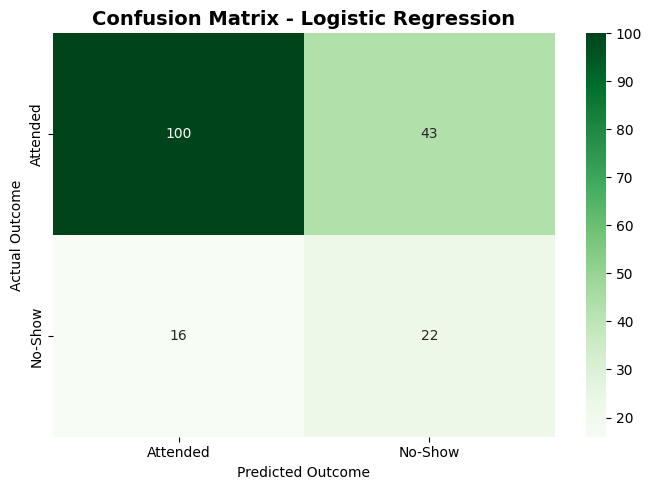

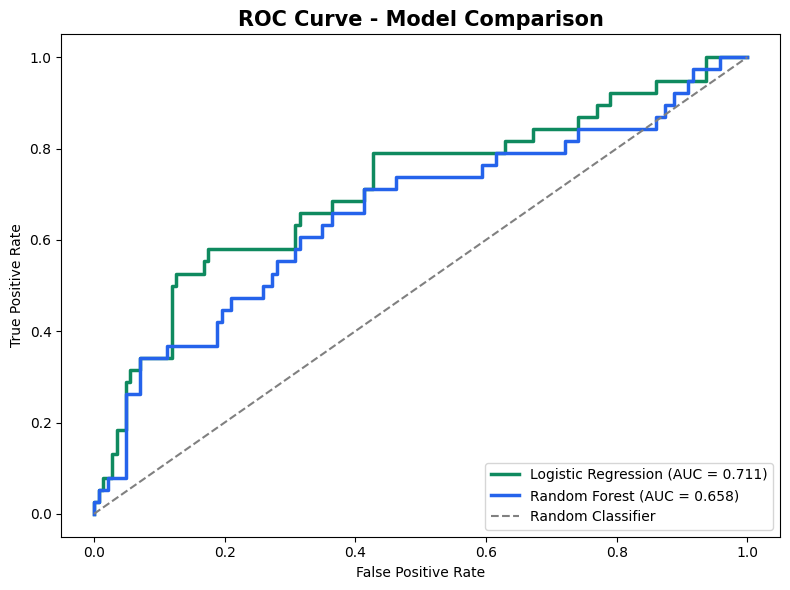

Model evaluation charts saved successfully!


In [12]:

# Step 7.10: Model Evaluation Visualizations

os.makedirs("/content/ml_outputs", exist_ok=True)

# Predictions from selected model
best_pred = best_model.predict(X_test)
best_prob = best_model.predict_proba(X_test)[:, 1]

# Confusion matrix
cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Attended", "No-Show"],
    yticklabels=["Attended", "No-Show"]
)

plt.title(
    f"Confusion Matrix - {best_model_name}",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.tight_layout()

plt.savefig(
    "/content/ml_outputs/01_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ROC Curve Comparison
plt.figure(figsize=(8, 6))

for name, probability, color in [
    ("Logistic Regression", lr_prob, "#0F8A5F"),
    ("Random Forest", rf_prob, "#2563EB")
]:

    fpr, tpr, _ = roc_curve(y_test, probability)
    auc = roc_auc_score(y_test, probability)

    plt.plot(
        fpr, tpr,
        linewidth=2.5,
        color=color,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.title("ROC Curve - Model Comparison",
          fontsize=15, fontweight="bold")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    "/content/ml_outputs/02_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Model evaluation charts saved successfully!")


In [13]:

# Step 7.11: Export Machine Learning Model

import shutil
import json
import sklearn

output_dir = "/content/ml_outputs"

os.makedirs(output_dir, exist_ok=True)

# Save trained model with preprocessing
joblib.dump(
    best_model,
    f"{output_dir}/best_model.pkl"
)

# Save performance reports
cv_report.to_csv(
    f"{output_dir}/cross_validation_report.csv",
    index=False
)

comparison_df.to_csv(
    f"{output_dir}/model_comparison.csv",
    index=False
)

# Save model information
metadata = {
    "model_name": best_model_name,
    "features": features,
    "numerical_features": numerical_features,
    "categorical_features": categorical_features,
    "training_records": len(X_train),
    "testing_records": len(X_test),
    "test_accuracy": float(
        accuracy_score(y_test, best_pred)
    ),
    "test_roc_auc": float(
        roc_auc_score(y_test, best_prob)
    ),
    "sklearn_version": sklearn.__version__,
    "purpose": "Academic prototype only"
}

with open(
    f"{output_dir}/model_metadata.json", "w"
) as file:
    json.dump(metadata, file, indent=4)

# Verify saved model
loaded_model = joblib.load(
    f"{output_dir}/best_model.pkl"
)

assert np.array_equal(
    loaded_model.predict(X_test),
    best_pred
)

print("MODEL EXPORT REPORT")
print("=" * 45)

for filename in sorted(os.listdir(output_dir)):
    print(filename)

print("\nSaved model verification: PASS")
print("Notebook 03 completed successfully!")

# Download ZIP backup
shutil.make_archive(
    "/content/ml_outputs",
    "zip",
    output_dir
)

files.download("/content/ml_outputs.zip")


MODEL EXPORT REPORT
01_confusion_matrix.png
02_roc_curve.png
best_model.pkl
cross_validation_report.csv
model_comparison.csv
model_metadata.json

Saved model verification: PASS
Notebook 03 completed successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>